In [10]:
!pip install keras_tuner

In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import keras_tuner as kt

# Load dataset
data = pd.read_excel(r'kc_house_data_yr.xlsx')

# Features and target
X = data.drop("price", axis=1).values
y = data["price"].values

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Define a model builder for Keras Tuner
def model_builder(hp):
    model = keras.Sequential()

    # Choose number of layers between 1-3
    for i in range(hp.Int('num_layers', 1, 3)):
        model.add(layers.Dense(
            units=hp.Int(f'units_{i}', min_value=32, max_value=256, step=32),
            activation='relu'))

        # Optionally add dropout
        if hp.Boolean(f'dropout_{i}'):
            model.add(layers.Dropout(rate=hp.Choice(f'dropout_rate_{i}', [0.2, 0.3, 0.4])))

    # Output layer for regression
    model.add(layers.Dense(1, activation='linear'))

    # Tune learning rate
    hp_learning_rate = hp.Choice('learning_rate', [1e-2, 1e-3, 1e-4])

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=hp_learning_rate),
                  loss='mse',
                  metrics=['mae'])

    return model

# Initialize tuner
tuner = kt.RandomSearch(
    model_builder,
    objective='val_mae',
    max_trials=5,  # number of hyperparameter settings to try
    executions_per_trial=2,  # run each model more than once for robustness
    directory='house_tuning',
    project_name='kc_house_regression'
)

# Perform hyperparameter search
tuner.search(X_train, y_train, epochs=50, validation_split=0.2, verbose=1)

# Get best model
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best hyperparameters:")
print(f"Layers: {best_hps.get('num_layers')}")
for i in range(best_hps.get('num_layers')):
    print(f"Units layer {i}: {best_hps.get(f'units_{i}')}, Dropout: {best_hps.get(f'dropout_{i}')}") # Units = # neurons per layer
print(f"Learning Rate: {best_hps.get('learning_rate')}")

# Build and train the best model
model = tuner.hypermodel.build(best_hps)
history = model.fit(X_train, y_train, validation_split=0.2, epochs=100, verbose=1)

# Evaluate on test data
loss, mae = model.evaluate(X_test, y_test, verbose=0)
print(f"Test MAE: {mae:.2f}")


Trial 5 Complete [00h 03m 37s]
val_mae: 68547.578125

Best val_mae So Far: 68547.578125
Total elapsed time: 00h 15m 28s
Best hyperparameters:
Layers: 3
Units layer 0: 256, Dropout: False
Units layer 1: 96, Dropout: True
Units layer 2: 32, Dropout: False
Learning Rate: 0.01
Epoch 1/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 93491707904.0000 - mae: 187644.0781 - val_loss: 29154230272.0000 - val_mae: 109553.3750
Epoch 2/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 35061534720.0000 - mae: 118035.6406 - val_loss: 28042620928.0000 - val_mae: 106356.7734
Epoch 3/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 33518340096.0000 - mae: 114025.2500 - val_loss: 26541359104.0000 - val_mae: 104726.9141
Epoch 4/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 32903933952.0000 - mae: 113337.9375 - val_loss: 26308063232.0000 - val_mae: 104851.2188
Epoch 5/100
433/433 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 32563075072.0000 - mae: 112195.0781 - val_loss: 25909254144.0000 - va

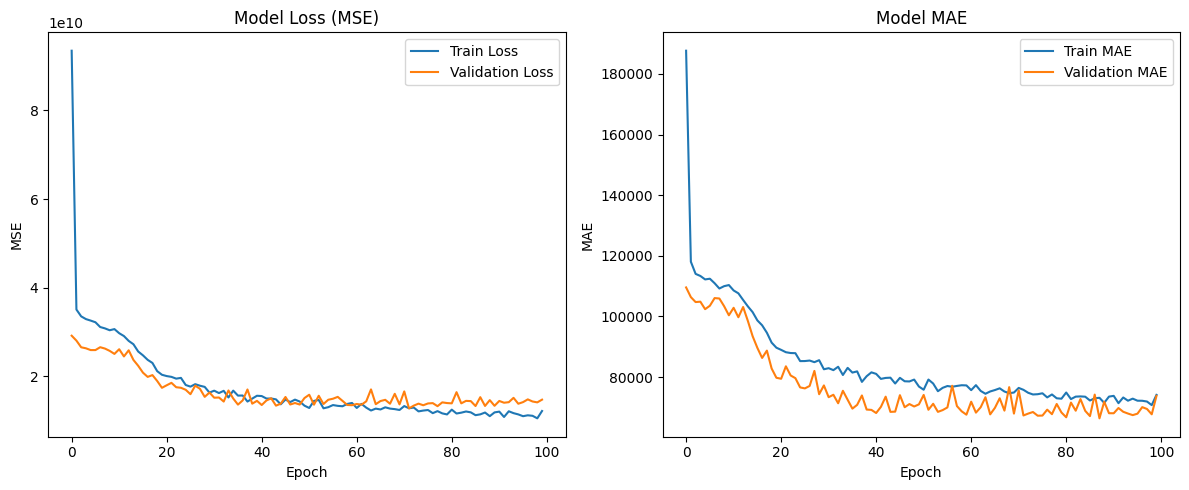

In [12]:
import matplotlib.pyplot as plt

# Plot training curves
plt.figure(figsize=(12,5))


plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()


plt.subplot(1,2,2)
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title('Model MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()


plt.tight_layout()
plt.show()

### Training the best model

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Load dataset
data = pd.read_excel(r'kc_house_data_yr.xlsx')

# Features and target
X = data.drop("price", axis=1).values
y = data["price"].values

# Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Build model with best hyperparameters
model = keras.Sequential()
model.add(layers.Dense(32, activation='relu'))
model.add(layers.Dense(192, activation='relu'))
model.add(layers.Dense(192, activation='relu'))
model.add(layers.Dropout(0.3))   # dropout after last layer
model.add(layers.Dense(1, activation='linear'))

# Compile
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss='mse',
    metrics=['mae']
)

# Early stopping
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

# Train
history = model.fit(
    X, y,
    epochs=500,
    batch_size=32,
    validation_split=0.2,   # still recommended even if you don’t split manually
    callbacks=[early_stop],
    verbose=1
)

# Plot learning curves
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title('Model MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()

plt.tight_layout()
plt.show()


Epoch 1/500
531/541 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 147053720994.4708 - mae: 261129.9138

KeyboardInterrupt: 

Exercise !

- Do the exercise with 3, 5 and 8 trial, graph the results and report the table for every case !

In [ ]:
import time
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras_tuner as kt
from tensorflow import keras

# Definimos una lista para almacenar los resultados para la tabla y la gráfica
results = []

# Definimos los diferentes números de trials que queremos probar
trials_to_test = [3, 5, 8]

for num_trials in trials_to_test:
    print(f"\n=== Iniciando búsqueda con max_trials = {num_trials} ===\n")
    start_time = time.time()

    # Inicializamos el sintonizador de Keras Tuner para este experimento
    tuner = kt.RandomSearch(
        model_builder,
        objective='val_mae',
        max_trials=num_trials,
        executions_per_trial=1,  # 1 ejecución por prueba para ahorrar tiempo en Colab
        directory=f'house_tuning_{num_trials}_trials',
        project_name=f'kc_house_regression_{num_trials}',
        overwrite=True
    )

    # Buscamos los mejores hiperparámetros
    tuner.search(X_train, y_train, epochs=40, validation_split=0.2, verbose=0)
    elapsed_time = time.time() - start_time

    # Obtenemos los mejores hiperparámetros
    best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

    # Construimos y entrenamos el mejor modelo
    best_model = tuner.hypermodel.build(best_hps)
    best_model.fit(X_train, y_train, validation_split=0.2, epochs=60, verbose=0)

    # Evaluamos en el conjunto de test
    loss, test_mae = best_model.evaluate(X_test, y_test, verbose=0)

    print(f"Finalizado en {elapsed_time:.1f} segundos. Test MAE: {test_mae:.2f}")

    # Guardamos las métricas claves
    results.append({
        'Trials': num_trials,
        'Test MAE': test_mae,
        'Tiempo de búsqueda (seg)': round(elapsed_time, 2),
        'Num Capas': best_hps.get('num_layers'),
        'LR Seleccionado': best_hps.get('learning_rate')
    })

# Convertimos a DataFrame para visualizar la tabla comparativa
df_results = pd.DataFrame(results)
display(df_results)


=== Iniciando búsqueda con max_trials = 3 ===



In [ ]:
# Graficamos los resultados comparando el Test MAE de cada experimento
plt.figure(figsize=(10, 6))
bars = plt.bar(df_results['Trials'].astype(str), df_results['Test MAE'], color=['#4F81BD', '#C0504D', '#9BBB59'], width=0.5)

plt.title('Comparación del MAE de Test por Cantidad de Trials (Keras Tuner)', fontsize=14, fontweight='bold')
plt.xlabel('Número de Trials en la búsqueda', fontsize=12)
plt.ylabel('Test MAE (Menor es mejor)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Añadimos los valores numéricos sobre cada barra para una lectura rápida
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + (yval * 0.01), f'${yval:,.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()